<a href="https://colab.research.google.com/github/Harshada1301/data-analysis-agent/blob/main/data_analysis_agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q langchain langchain-experimental langchain-google-genai langchain-community pandas matplotlib tabulate

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_experimental.agents import create_pandas_dataframe_agent

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vivek468/superstore-dataset-final")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
Path to dataset files: /kaggle/input/superstore-dataset-final


In [ ]:
df = pd.read_csv(f'{path}/Sample - Superstore.csv', encoding="latin-1")
df["Order Date"] = pd.to_datetime(df["Order Date"])
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", timeout=60, max_retries=2)

agent = create_pandas_dataframe_agent(
    llm,
    df,
    verbose=True,
    allow_dangerous_code=True,
    agent_type="tool-calling",
    max_iterations=8,
    max_execution_time=90,
    prefix="When calling python_repl_ast, always pass a single string in the argument named 'query' (not 'queries'). Use the dataframe called df.",
)

In [ ]:
def ask(question, tries=3):
    for i in range(tries):
        try:
            response = agent.invoke(question)
            out = response["output"]
            if isinstance(out, list):
                out = "".join(b.get("text", "") for b in out if isinstance(b, dict))
            print("\nANSWER:", out)
            return
        except Exception as e:
            print(f"Attempt {i+1} failed: {str(e)[:100]}")
    print("All attempts failed. Try a stronger model (see below).")

In [ ]:
ask("Which category has the highest total profit?")
ask("Which 5 customers have the highest total sales?")
ask("Which region has the lowest profit?")



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': 'profit_by_cat = df.groupby(\'Category\')[\'Profit\'].sum()\nprint(profit_by_cat)\nprint("Highest profit category:", profit_by_cat.idxmax())\n'}`


Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64
Highest profit category: Technology
[{'type': 'text', 'text': 'Based on the dataset, the category with the highest total profit is **Technology**.', 'index': 0, 'extras': {'signature': 'EowBCokBAWkUfROaRfVdQC6H+YSRXHvZ7QqnoxIsKWqLhbU0pdPTs9LW33UQGWSDVzarSOq4JJjMpnbTny7sTgLDK19p0bZo2GDMD8kmp6CRI4yR+YNqAt6qIUp3i6T8q0dc4oMQKpwCSv+FBAb9YlvwKZlqgIAAaqq2gyrIkerCgsG1LcWhy0Bt8p28kV8='}}]

> Finished chain.

ANSWER: Based on the dataset, the category with the highest total profit is **Technology**.


> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "top_5 = df.groupby(['Customer ID', 'Customer Name'])['S



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "import pandas as pd\nimport matplotlib.pyplot as plt\n\n# Ensure Order Date is datetime\ndf['Order Date'] = pd.to_datetime(df['Order Date'])\n\n# Resample or group by month\nmonthly_sales = df.set_index('Order Date').resample('M')['Sales'].sum()\n\n# Plotting\nplt.figure(figsize=(10, 6))\nplt.plot(monthly_sales.index, monthly_sales.values, marker='o')\nplt.title('Monthly Total Sales')\nplt.xlabel('Order Date')\nplt.ylabel('Sales')\nplt.grid(True)\nplt.tight_layout()\nplt.show()"}`




<string>:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.


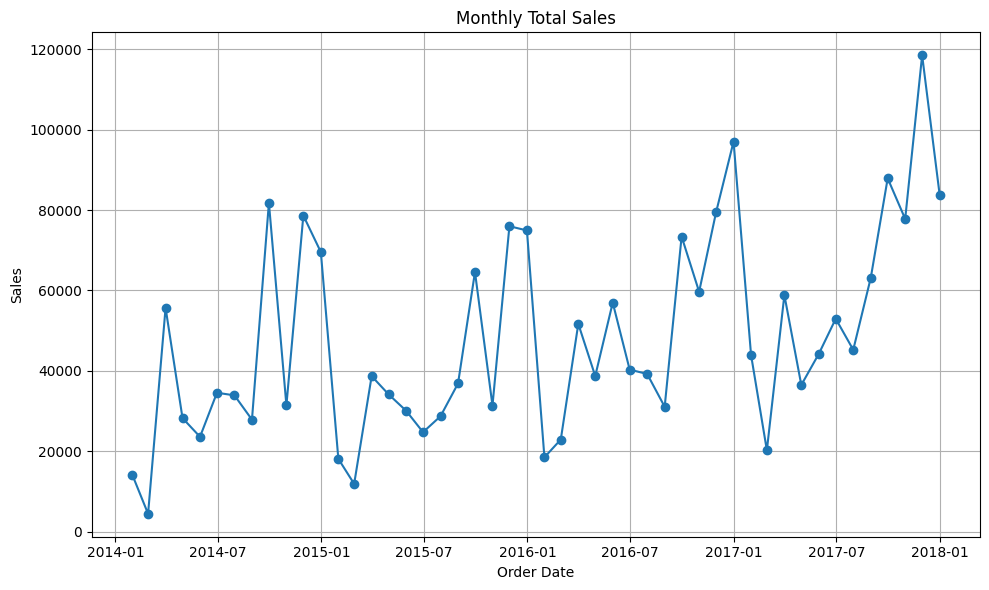

[{'type': 'text', 'text': "```python\nimport pandas as pd\nimport matplotlib.pyplot as plt\n\n# Ensure Order Date is datetime and set as index to resample by month\ndf['Order Date'] = pd.to_datetime(df['Order Date'])\nmonthly_sales = df.set_index('Order Date').resample('M')['Sales'].sum()\n\n# Plot monthly total sales as a line chart\nplt.figure(figsize=(10, 6))\nplt.plot(monthly_sales.index, monthly_sales.values, marker='o')\nplt.title('Monthly Total Sales')\nplt.xlabel('Order Date')\nplt.ylabel('Total Sales')\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n```", 'index': 0, 'extras': {'signature': 'EowBCokBAWkUfRMMXHFoEoiJiPbfImC2RXTB7yNKN2Rm0TWCPWka+2P+xvlAPMHIQowDA2teYsl16y1KhxIA0yaTSxM4pEdI4tf5rIUnzBUi7tQIIRVpQljZUOXO6WPVuKytc7Pr9z9zJsn9LImwHAyp3JPav+Mr+wGRCM7VFpp2E6d3fZ2m26qMXm1inAI='}}]

> Finished chain.

ANSWER: ```python
import pandas as pd
import matplotlib.pyplot as plt

# Ensure Order Date is datetime and set as index to resample by month
df['Order Date'] = pd.to_datetime

In [ ]:
ask("Plot monthly total sales as a line chart using matplotlib and call plt.show()")

/tmp/ipykernel_455/3588974364.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = df.set_index("Order Date")["Sales"].resample("M").sum()


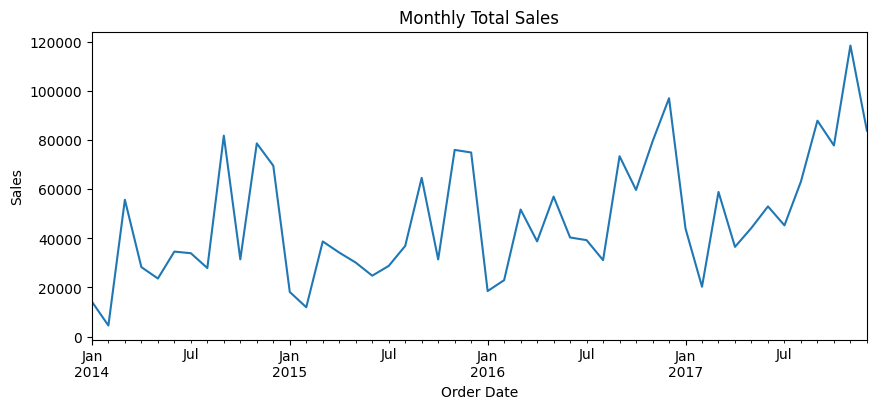

In [ ]:
monthly = df.set_index("Order Date")["Sales"].resample("M").sum()
monthly.plot(kind="line", figsize=(10, 4), title="Monthly Total Sales")
plt.ylabel("Sales")
plt.show()